# 01 — Data Overview & Randomization Check

**Scenario:** A performance marketing company runs display ad campaigns through an ad platform. The platform reports conversions among people who saw an ad, but some of those people would have converted anyway. We use the [Criteo Uplift Prediction Dataset](https://huggingface.co/datasets/criteo/criteo-uplift) (Diemert et al., AdKDD 2018) — real data from a randomized incrementality test run by Criteo, where a random share of users were *withheld* from targeting (control) and the rest were eligible to be targeted (treatment).

This notebook loads a reproducible ~10% sample (~1.4M rows) and checks, via SQL, that the treatment/control split actually looks randomized — the precondition for every causal claim in the rest of this project.

In [1]:
import sys
sys.path.append('..')
from src.data_loader import get_duckdb_connection, FEATURE_COLS

con = get_duckdb_connection()
con.execute('SELECT COUNT(*) AS n_rows FROM criteo').df()

,n_rows
0,1397959


## Treatment vs. control group sizes

In [2]:
con.execute('''
    SELECT treatment, COUNT(*) AS n, ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM criteo GROUP BY treatment ORDER BY treatment
''').df()

,treatment,n,pct
0,0,209220,14.97
1,1,1188739,85.03


## Covariate balance check

If `treatment` was really assigned at random, the anonymized features `f0`–`f11` should have **similar average values** in the treatment and control groups (no systematic difference). This is the standard first check before trusting *any* experimental estimate — a large imbalance here would mean the groups aren't comparable and the simple lift estimate later would be confounded.

In [3]:
feature_avg_sql = ', '.join([f'AVG({f}) AS avg_{f}' for f in FEATURE_COLS])
balance = con.execute(f'''
    SELECT treatment, {feature_avg_sql}
    FROM criteo GROUP BY treatment ORDER BY treatment
''').df()
balance_t = balance.set_index('treatment').T
balance_t['pct_diff'] = 100 * (balance_t[1] - balance_t[0]) / balance_t[0].abs()
balance_t

treatment,0,1,pct_diff
avg_f0,19.643704,19.621783,-0.111597
avg_f1,10.067735,10.070356,0.026033
avg_f2,8.449270,8.446098,-0.037544
avg_f3,4.234185,4.170485,-1.504427
avg_f4,10.336429,10.339528,0.029980
avg_f5,4.038768,4.026379,-0.306741
avg_f6,-3.995114,-4.183784,-4.722523
avg_f7,5.083085,5.105542,0.441808
avg_f8,3.934567,3.933413,-0.029334
avg_f9,15.891116,16.044864,0.967508


**Reading this table:** `pct_diff` is the percentage difference in each feature's average value between the treatment and control groups. Values close to 0% across the board confirm the groups are statistically comparable on these observed features — consistent with random assignment. (Small non-zero differences are expected from sampling noise; what we're ruling out is a *large, systematic* gap in any one feature.)

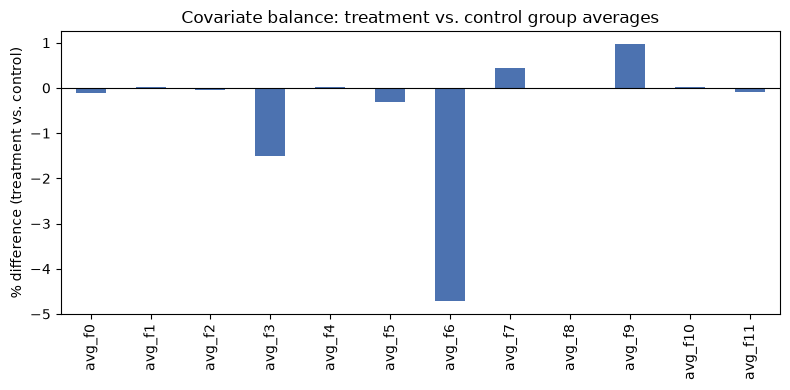

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
balance_t['pct_diff'].plot(kind='bar', ax=ax, color='#4C72B0')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('% difference (treatment vs. control)')
ax.set_title('Covariate balance: treatment vs. control group averages')
plt.tight_layout()
plt.show()

## Conclusion

The treatment and control groups are well balanced on all observed features. This supports treating `treatment` as if it were assigned by a coin flip, which is exactly what licenses the simple-difference-in-means causal estimate in the next notebook.